In [33]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
from pathlib import Path
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from scipy import stats
from notebooks.imports import *

from src.utils import pmf_utils

### Config

In [35]:
from config import dir_config, main_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)


### Utils functions

In [36]:
def plot_psych(x, y, x_hat, y_hat):
    fig, ax = plt.subplots()
    ax.plot(x, y, 'o', label='Original Data')
    ax.plot(x_hat, y_hat, 'r-', label='Fitted Curve')
    ax.set_xlabel('Coherence')
    ax.set_ylabel('Probability of Correct Response')
    ax.set_xlim(-100, 100)
    ax.set_ylim(0, 1)
    ax.legend()
    plt.show()


def plot_pulse_psych(psych_curves, ms=10, lw=3, alpha=1, suptitle='', fig=None, ax=None, legend=True):
    if (ax is None) or (fig is None):
        fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    # early pulse
    if 1 in psych_curves.keys():
        ax[0].plot(psych_curves[0]['x'], psych_curves[0]['y'], 'ko', ms=ms, alpha=alpha)
        ax[0].plot(psych_curves[0]['x_hat'], psych_curves[0]['y_hat'], 'k-', lw=lw, alpha=alpha, label='Control')
        ax[0].plot(psych_curves[1]['x'], psych_curves[1]['y'], 'bo', ms=ms, alpha=alpha)
        ax[0].plot(psych_curves[1]['x_hat'], psych_curves[1]['y_hat'], 'b-', lw=lw, alpha=alpha, label='Early Positive')
        ax[0].plot(psych_curves[-1]['x'], psych_curves[-1]['y'], 'ro', ms=ms, alpha=alpha)
        ax[0].plot(psych_curves[-1]['x_hat'], psych_curves[-1]['y_hat'], 'r-', lw=lw, alpha=alpha, label='Early Negative')
        ax[0].set_xlabel('Coherence')
        ax[0].set_ylabel('Probability of Positive Response', fontsize=16)
        ax[0].legend() if legend else None
        ax[0].set_title('Early Pulse', fontsize=22)
        ax[0].set_xlim(-105, 105)
        ax[0].set_ylim(-0.05, 1.05)
        ax[0].set_xticks([-100, -35, -13, 0, 13, 35, 100])
        ax[0].tick_params(axis='both', labelsize=16)
        ax[0].spines['top'].set_visible(False)
        ax[0].spines['right'].set_visible(False)
        ax[0].grid(False)

    # mid pulse
    if 2 in psych_curves.keys():
        ax[1].plot(psych_curves[0]['x'], psych_curves[0]['y'], 'ko', ms=ms, alpha=alpha)
        ax[1].plot(psych_curves[0]['x_hat'], psych_curves[0]['y_hat'], 'k-', lw=lw, alpha=alpha, label='Control')
        ax[1].plot(psych_curves[2]['x'], psych_curves[2]['y'], 'bo', ms=ms, alpha=alpha)
        ax[1].plot(psych_curves[2]['x_hat'], psych_curves[2]['y_hat'], 'b-', lw=lw, alpha=alpha, label='Mid Positive')
        ax[1].plot(psych_curves[-2]['x'], psych_curves[-2]['y'], 'ro', ms=ms, alpha=alpha)
        ax[1].plot(psych_curves[-2]['x_hat'], psych_curves[-2]['y_hat'], 'r-', lw=lw, alpha=alpha, label='Mid Negative')
        ax[1].set_xlabel('Coherence')
        ax[1].set_ylabel('Probability of Positive Response', fontsize=16)
        ax[1].set_ylim(0, 1)
        ax[1].legend() if legend else None
        ax[1].set_title('Mid Pulse', fontsize=22)
        ax[1].set_xlim(-105, 105)
        ax[1].set_ylim(-0.05, 1.05)
        ax[1].set_xticks([-100, -35, -13, 0, 13, 35, 100])
        ax[1].tick_params(axis='both', labelsize=16)
        ax[1].spines['top'].set_visible(False)
        ax[1].spines['right'].set_visible(False)
        ax[1].grid(False)

    # late pulse
    if 3 in psych_curves.keys():
        ax[2].plot(psych_curves[0]['x'], psych_curves[0]['y'], 'ko', ms=ms, alpha=alpha)
        ax[2].plot(psych_curves[0]['x_hat'], psych_curves[0]['y_hat'], 'k-', lw=lw, alpha=alpha, label='Control')
        ax[2].plot(psych_curves[3]['x'], psych_curves[3]['y'], 'bo', ms=ms, alpha=alpha)
        ax[2].plot(psych_curves[3]['x_hat'], psych_curves[3]['y_hat'], 'b-', lw=lw, alpha=alpha, label='late Positive')
        ax[2].plot(psych_curves[-3]['x'], psych_curves[-3]['y'], 'ro', ms=ms, alpha=alpha)
        ax[2].plot(psych_curves[-3]['x_hat'], psych_curves[-3]['y_hat'], 'r-', lw=lw, alpha=alpha, label='late Negative')
        ax[2].set_xlabel('Coherence')
        ax[2].set_ylabel('Probability of Positive Response', fontsize=16)
        ax[2].set_ylim(0, 1)
        ax[2].legend() if legend else None
        ax[2].set_title('Late Pulse', fontsize=22)
        ax[2].set_xlim(-105, 105)
        ax[2].set_ylim(-0.05, 1.05)
        ax[2].set_xticks([-100, -35, -13, 0, 13, 35, 100])
        ax[2].tick_params(axis='both', labelsize=16)
        ax[2].spines['top'].set_visible(False)
        ax[2].spines['right'].set_visible(False)
        ax[2].grid(False)

    if suptitle:
        fig.suptitle(suptitle)

    return fig, ax


#### Pulse types
- -3: 'late_negative_pulse'
- -2: 'middle_negative_pulse'
- -1: 'early_negative_pulse'
- 0: 'control'
- 1: 'early_positive_pulse'
- 2: 'middle_positive_pulse'
- 3: 'late_positive_pulse'


### Load data

In [37]:
data = pd.read_csv(Path(processed_dir, 'valid_data.csv'), index_col=None)

data = data[data['subject_id'] != "DBM6"]

data.head()

,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,pulse_type
0,0,uw,DBM11,10_1,1,0,False,100,1,1.0,1.080817,1.0,1.5,0.530901,25.0,0.0,0.500000,True,0.41675,0.06668,-100,-3.0
1,0,uw,DBM11,10_1,2,0,False,100,1,-1.0,0.469520,0.0,NaN,0.577326,25.0,0.0,13.689771,False,0.41675,0.06668,100,0.0
2,0,uw,DBM11,10_1,3,0,False,-100,-1,-1.0,2.171707,1.0,1.5,0.556890,25.0,0.0,0.500000,True,0.41675,0.06668,100,3.0
3,0,uw,DBM11,10_1,4,0,False,-100,-1,-1.0,0.476003,1.0,1.5,0.548262,25.0,0.0,0.500000,False,0.05001,0.06668,-100,-0.0
4,0,uw,DBM11,10_1,5,0,False,-100,-1,-1.0,0.971870,1.0,1.5,0.561377,25.0,0.0,0.500000,False,0.23338,0.06668,-100,-0.0


In [38]:
subject_sessions = (data.groupby('subject_id')['session_id'].nunique().reset_index(name='count'))
subject_sessions

,subject_id,count
0,DBM11,15
1,DBM12,17
2,DBM13,5
3,DBM14,16
4,DBM15,33
5,DBM16,9
6,DBM5,23
7,DBM8,13
8,PSUIM10,8
9,PSUIM5,10


### Plot psychometric functions

In [39]:
data.shape

(99599, 22)

In [40]:
# run utils.get_psychometric_curve function for each subset of pulse_type
psych_curves = {}

for pulse_type in data.pulse_type.unique():
    x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(data[data.pulse_type == pulse_type])

    psych_curves[pulse_type] = {
        'x': x,
        'y': y,
        'model': model,
        'x_hat': x_hat,
        'y_hat': y_hat
    }


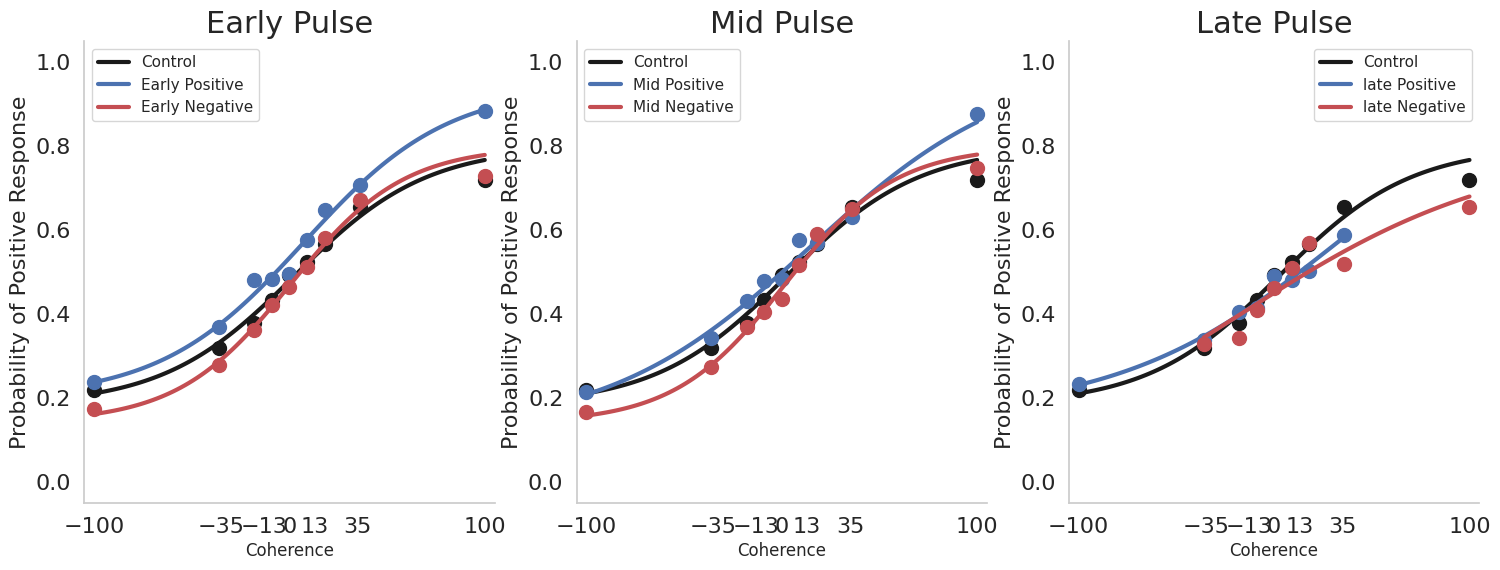

In [41]:
plot_pulse_psych(psych_curves);